In [1]:
!pip install -q transformers datasets accelerate scikit-learn

In [2]:
import numpy as np, pandas as pd, time, torch
import matplotlib.pyplot as plt, seaborn as sns
from collections import Counter
from datasets import load_dataset

In [3]:
data = load_dataset("SetFit/amazon_reviews_multi_en")
print(data)
print(data["train"][0])

README.md:   0%|          | 0.00/28.0 [00:00<?, ?B/s]

train.jsonl: reconstructing file:   0%|          |  0.00B / 47.4MB            

train.jsonl: downloading bytes:           |  0.00B            

validation.jsonl:   0%|          | 0.00/1.19M [00:00<?, ?B/s]

test.jsonl:   0%|          | 0.00/1.18M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/200000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'text', 'label', 'label_text'],
        num_rows: 200000
    })
    validation: Dataset({
        features: ['id', 'text', 'label', 'label_text'],
        num_rows: 5000
    })
    test: Dataset({
        features: ['id', 'text', 'label', 'label_text'],
        num_rows: 5000
    })
})
{'id': 'en_0964290', 'text': "Arrived broken. Manufacturer defect. Two of the legs of the base were not completely formed, so there was no way to insert the casters. I unpackaged the entire chair and hardware before noticing this. So, I'll spend twice the amount of time boxing up the whole useless thing and send it back with a 1-star review of part of a chair I never got to sit in. I will go so far as to include a picture of what their injection molding and quality assurance process missed though. I will be hesitant to buy again. It makes me wonder if there aren't missing structures and supports that don't impede the assembly process.", 'label':

1    40000
2    40000
3    40000
4    40000
5    40000
Name: count, dtype: int64


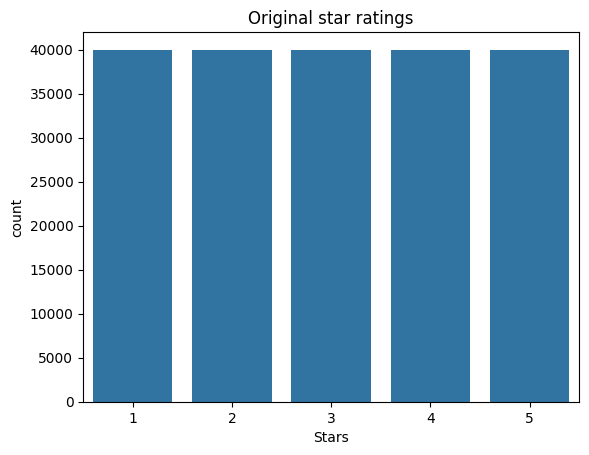

In [4]:
stars = pd.Series(data["train"]["label"]) + 1
print(stars.value_counts().sort_index())

sns.countplot(x=stars)
plt.title("Original star ratings")
plt.xlabel("Stars")
plt.show()

Map:   0%|          | 0/200000 [00:00<?, ? examples/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

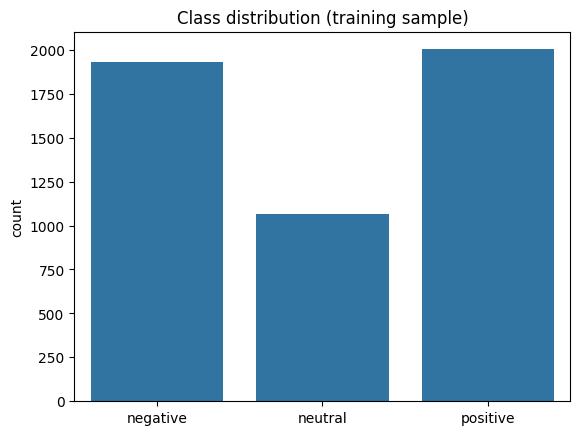

In [5]:
def to_3_class(x):
    s = x["label"]
    x["label"] = 0 if s < 2 else (1 if s == 2 else 2)
    return x

data = data.map(to_3_class)

train = data["train"].shuffle(seed=42).select(range(5000))
test  = data["test"].shuffle(seed=42).select(range(1000))

names = ["negative", "neutral", "positive"]
y_train = np.array(train["label"])
y_test  = np.array(test["label"])

sns.countplot(x=[names[i] for i in y_train], order=names)
plt.title("Class distribution (training sample)")
plt.show()

count    5000.000000
mean       34.452200
std        33.846075
min         3.000000
25%        13.000000
50%        24.000000
75%        45.000000
max       462.000000
Name: length, dtype: float64


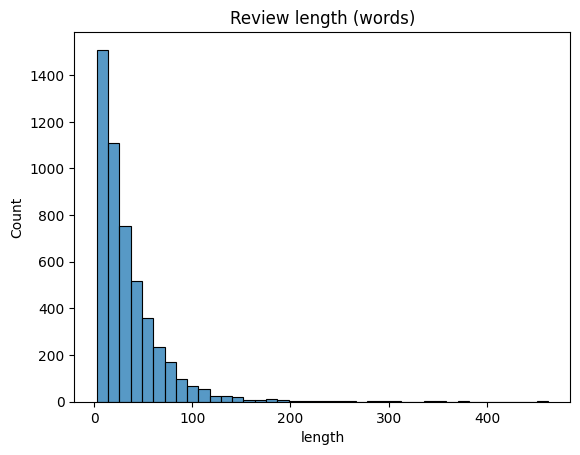

negative -> [('product', 313), ('like', 257), ('just', 238), ('work', 204), ('did', 185), ('use', 174), ('good', 167), ('time', 154)]
neutral -> [('like', 178), ('good', 158), ('just', 147), ('great', 128), ('product', 127), ('use', 122), ("it's", 112), ('really', 111)]
positive -> [('great', 534), ('good', 334), ('like', 322), ('love', 286), ('just', 232), ('use', 228), ('product', 210), ('easy', 202)]


In [6]:
df = pd.DataFrame({"text": train["text"], "label": [names[i] for i in y_train]})
df["length"] = df["text"].apply(lambda t: len(t.split()))

print(df["length"].describe())
sns.histplot(df["length"], bins=40)
plt.title("Review length (words)")
plt.show()

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
for n in names:
    words = " ".join(df[df.label == n]["text"]).lower().split()
    words = [w.strip(".,!?\"'()") for w in words]
    words = [w for w in words if w not in ENGLISH_STOP_WORDS and len(w) > 2]
    print(n, "->", Counter(words).most_common(8))

In [7]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

def tokenize(batch):
    return tokenizer(batch["text"], truncation=True,
                     padding="max_length", max_length=128)

train_bert = train.map(tokenize, batched=True)
test_bert  = test.map(tokenize, batched=True)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

In [8]:
from transformers import AutoModelForSequenceClassification, TrainingArguments, Trainer

model = AutoModelForSequenceClassification.from_pretrained(
    "bert-base-uncased", num_labels=3)

args = TrainingArguments(
    output_dir="bert_out",
    num_train_epochs=2,
    per_device_train_batch_size=16,
    learning_rate=2e-5,
    logging_steps=20,
    fp16=True,
    report_to="none"
)

trainer = Trainer(model=model, args=args, train_dataset=train_bert)

start = time.time()
trainer.train()
bert_train_time = time.time() - start
print("BERT training time (sec):", round(bert_train_time))

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/usr/local/lib/python3

Step,Training Loss
20,1.064345
40,1.024692
60,0.870932
80,0.823380
100,0.701236
120,0.699958
140,0.745301
160,0.668012
180,0.644582
200,0.666375


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

BERT training time (sec): 13927


In [9]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

bert_preds = np.argmax(trainer.predict(test_bert).predictions, axis=1)
bert_acc = accuracy_score(y_test, bert_preds)
bert_f1  = f1_score(y_test, bert_preds, average="macro")

print("BERT accuracy:", round(bert_acc, 3))
print(classification_report(y_test, bert_preds, target_names=names))

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


BERT accuracy: 0.732
              precision    recall  f1-score   support

    negative       0.77      0.79      0.78       392
     neutral       0.40      0.36      0.38       200
    positive       0.84      0.86      0.85       408

    accuracy                           0.73      1000
   macro avg       0.67      0.67      0.67      1000
weighted avg       0.72      0.73      0.73      1000



In [10]:
import tensorflow as tf

X_train = tf.constant(train["text"])
X_test  = tf.constant(test["text"])

vectorizer = tf.keras.layers.TextVectorization(max_tokens=10000,
                                               output_sequence_length=128)
vectorizer.adapt(X_train)

lstm = tf.keras.Sequential([
    vectorizer,
    tf.keras.layers.Embedding(10000, 64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.Dense(3, activation="softmax")
])

lstm.compile(loss="sparse_categorical_crossentropy",
             optimizer="adam", metrics=["accuracy"])

start = time.time()
history = lstm.fit(X_train, y_train, epochs=5, batch_size=32, validation_split=0.1)
lstm_train_time = time.time() - start
print("LSTM training time (sec):", round(lstm_train_time))

Epoch 1/5
141/141 ━━━━━━━━━━━━━━━━━━━━ 15s 88ms/step - accuracy: 0.3909 - loss: 1.0686 - val_accuracy: 0.3820 - val_loss: 1.0672
Epoch 2/5
141/141 ━━━━━━━━━━━━━━━━━━━━ 13s 93ms/step - accuracy: 0.3956 - loss: 1.0645 - val_accuracy: 0.3820 - val_loss: 1.0676
Epoch 3/5
141/141 ━━━━━━━━━━━━━━━━━━━━ 19s 84ms/step - accuracy: 0.4053 - loss: 1.0632 - val_accuracy: 0.3820 - val_loss: 1.0676
Epoch 4/5
141/141 ━━━━━━━━━━━━━━━━━━━━ 21s 85ms/step - accuracy: 0.4102 - loss: 1.0599 - val_accuracy: 0.3980 - val_loss: 1.0671
Epoch 5/5
141/141 ━━━━━━━━━━━━━━━━━━━━ 12s 85ms/step - accuracy: 0.4129 - loss: 1.0532 - val_accuracy: 0.3840 - val_loss: 1.0699
LSTM training time (sec): 80


In [11]:
lstm_preds = np.argmax(lstm.predict(X_test), axis=1)
lstm_acc = accuracy_score(y_test, lstm_preds)
lstm_f1  = f1_score(y_test, lstm_preds, average="macro")

print("LSTM accuracy:", round(lstm_acc, 3))
print(classification_report(y_test, lstm_preds, target_names=names))

32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 56ms/step
LSTM accuracy: 0.408
              precision    recall  f1-score   support

    negative       0.33      0.01      0.01       392
     neutral       0.40      0.02      0.04       200
    positive       0.41      0.99      0.58       408

    accuracy                           0.41      1000
   macro avg       0.38      0.34      0.21      1000
weighted avg       0.38      0.41      0.25      1000



In [12]:
def predict_bert(text):
    inputs = tokenizer(text, return_tensors="pt", truncation=True,
                       max_length=128).to(model.device)
    with torch.no_grad():
        return model(**inputs).logits.argmax().item()

samples = list(test["text"][:100])

start = time.time()
for s in samples:
    predict_bert(s)
bert_ms = (time.time() - start) / 100 * 1000

start = time.time()
for s in samples:
    lstm(tf.constant([s]), training=False)
lstm_ms = (time.time() - start) / 100 * 1000

table = pd.DataFrame({
    "Accuracy":            [bert_acc, lstm_acc],
    "Macro F1":            [bert_f1, lstm_f1],
    "Parameters":          [model.num_parameters(), lstm.count_params()],
    "Train time (s)":      [bert_train_time, lstm_train_time],
    "Latency (ms/review)": [bert_ms, lstm_ms],
}, index=["BERT", "LSTM"]).round(3)

print(table)

      Accuracy  Macro F1  Parameters  Train time (s)  Latency (ms/review)
BERT     0.732     0.670   109484547       13926.821              220.954
LSTM     0.408     0.209      673219          79.916              548.792


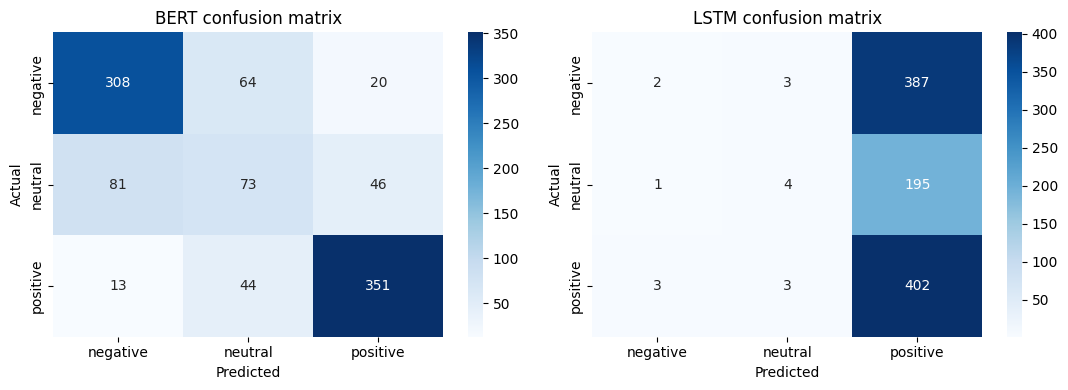

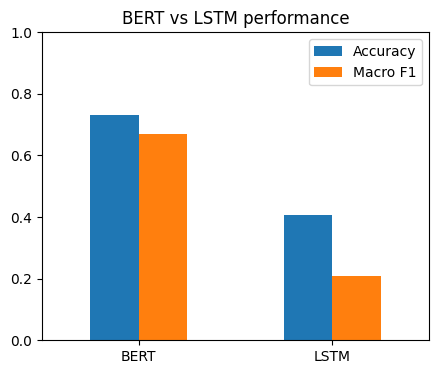

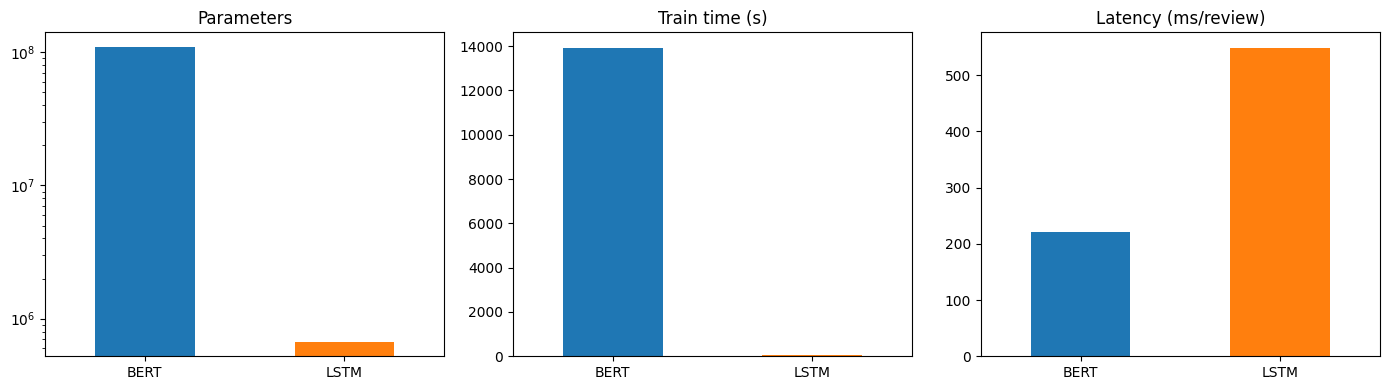

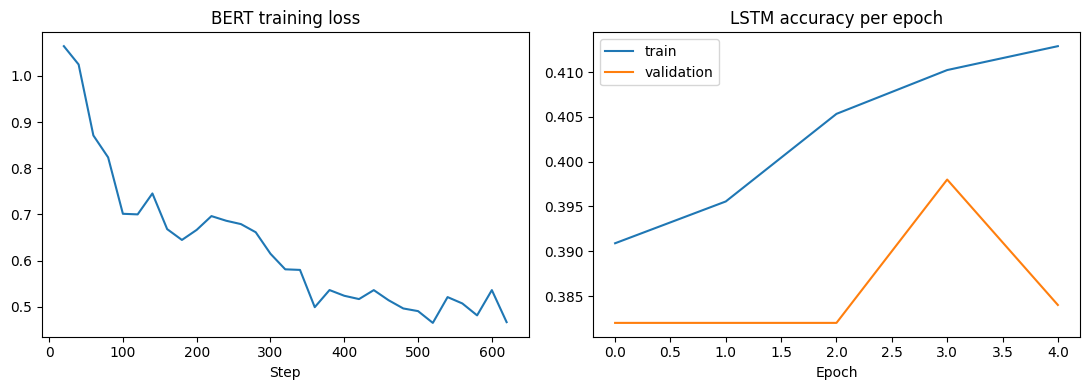

In [13]:

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, preds, title in zip(axes, [bert_preds, lstm_preds], ["BERT", "LSTM"]):
    sns.heatmap(confusion_matrix(y_test, preds), annot=True, fmt="d", cmap="Blues",
                xticklabels=names, yticklabels=names, ax=ax)
    ax.set_title(title + " confusion matrix")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()


table[["Accuracy", "Macro F1"]].plot(kind="bar", figsize=(5, 4), ylim=(0, 1))
plt.title("BERT vs LSTM performance"); plt.xticks(rotation=0); plt.show()


fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["Parameters", "Train time (s)", "Latency (ms/review)"]):
    table[col].plot(kind="bar", ax=ax, color=["tab:blue", "tab:orange"])
    ax.set_title(col); ax.tick_params(axis="x", rotation=0)
    if col == "Parameters":
        ax.set_yscale("log")
plt.tight_layout(); plt.show()


fig, axes = plt.subplots(1, 2, figsize=(11, 4))
logs = [x for x in trainer.state.log_history if "loss" in x]
axes[0].plot([x["step"] for x in logs], [x["loss"] for x in logs])
axes[0].set_title("BERT training loss"); axes[0].set_xlabel("Step")
axes[1].plot(history.history["accuracy"], label="train")
axes[1].plot(history.history["val_accuracy"], label="validation")
axes[1].set_title("LSTM accuracy per epoch"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout(); plt.show()

In [14]:
for text in ["Battery dies in one hour, total waste of money",
             "Works fine, nothing special",
             "Absolutely love this phone!"]:
    print(text, "->", names[predict_bert(text)])

Battery dies in one hour, total waste of money -> negative
Works fine, nothing special -> neutral
Absolutely love this phone! -> positive


In [15]:
wrong = np.where(bert_preds != y_test)[0][:5]
for i in wrong:
    print("Review :", test["text"][i][:150])
    print("Actual :", names[y_test[i]], "| Predicted:", names[bert_preds[i]], "\n")

Review : I loved the hat but I have a wider face. The bill didn’t quite look right- was too narrow for my face so I returned it.
Actual : negative | Predicted: neutral 

Review : I love what this is, but... I placed the stand on a white dresser and it stained it. Then I tried to get it off and no luck. Great size though
Actual : positive | Predicted: neutral 

Review : Slightly lightweight but otherwise perfect item. I do wish it had a weighted base cell when you are pulling out toilet paper that stuck can won't wobb
Actual : positive | Predicted: neutral 

Review : This harness broke the first time we tried to use it. It was easy to put on and seemed comfortable for my mom's 13 year old labrador but it tore the f
Actual : neutral | Predicted: negative 

Review : Arrived as advertised.
Actual : neutral | Predicted: positive 

